# Paywall test readout: highlighting the annual plan

**Question.** Should the web paywall present the annual plan as the recommended option?
`annual_highlight` does; `control` is the paywall as it was. The test ran on web signups in
March and April 2026, split 50/50.

**Answer.** Yes, ship it, and read it again when the first annual renewals come due. The variant
moved the annual share from 14.7% to 25.9% and added \$6.01 of revenue per signup over 180 days
(95% CI \$3.69 to \$8.34), without hurting paid conversion. The 30-day number the mart carries
(+\$8.65, +53%) overstates the gain, because an annual plan collects twelve months on day one.

Inputs are the dbt marts (`fct_experiment_exposures`, `fct_payments`, `dim_customers`,
`fct_web_funnel_daily`, `fct_web_sessions`). The statistics live in `analysis/experiment.py`
and are unit tested in `tests/test_experiment_stats.py`; this notebook only applies them.
The figures quoted in the text are for the default dataset (`make data`, seed 42); every code
cell recomputes them from the warehouse, and CI executes the notebook on a smaller dataset.

In [1]:
import os
import sys
import warnings
from pathlib import Path

import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "transform" / "dbt_project.yml").exists())
sys.path.insert(0, str(ROOT))

from analysis.experiment import (  # noqa: E402
    achieved_power,
    bootstrap_diff_ci,
    cuped_adjust,
    difference_in_means,
    minimum_detectable_effect,
    required_sample_size,
    srm_test,
)

warnings.filterwarnings("ignore", message=".*pandas only supports SQLAlchemy.*")
con = duckdb.connect(os.environ.get("DUCKDB_PATH", str(ROOT / "data" / "warehouse.duckdb")), read_only=True)

ALPHA = 0.05
HORIZON_DAYS = 180
GUARDRAIL_MARGIN = 0.02  # a drop of more than 2 points in paid conversion blocks the launch
CONTROL, TREATMENT = "control", "annual_highlight"
COLORS = {CONTROL: "#2a78d6", TREATMENT: "#eb6834"}
LABELS = {CONTROL: "Control", TREATMENT: "Annual highlight"}
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 110,
        "font.size": 10,
        "text.color": INK,
        "axes.edgecolor": GRID,
        "axes.labelcolor": MUTED,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.major.size": 0,
        "ytick.major.size": 0,
        "lines.linewidth": 2,
        "legend.frameon": False,
    }
)


def pct(x, digits=1):
    return f"{100 * x:.{digits}f}%"


def pp(x, digits=1):
    return f"{100 * x:+.{digits}f} pp"


def usd(x, signed=False):
    sign = ("+" if x >= 0 else "-") if signed else ("-" if x < 0 else "")
    return f"{sign}${abs(x):.2f}"

## 1. Decision rule

Stated before any outcome is computed, so the result cannot choose its own metric.

| Role | Metric | Rule |
|---|---|---|
| Primary | Revenue per exposed signup in the first 180 days, USD at constant FX | Ship if the 95% interval of the difference is above zero |
| Mechanism | Share of signups choosing the annual plan | Expected to rise; if it does not, a revenue gain is not explained by the change |
| Guardrail | Share of signups that pay within 14 days | Do not ship if a drop of more than 2 points cannot be ruled out (interval reaching below -2 pp) |
| Validity | Sample ratio, balance of pre-assignment attributes | If they fail, stop: no estimate is read |

The unit of analysis is the customer, which is also the unit of randomisation, so no clustering
correction is needed. All tests are two-sided at alpha = 5%, fixed horizon: the test ran its planned
61 days and is read once, so there is no peeking correction to make.

Why 180 days and not the 30-day revenue in the mart: the two arms sell a different mix of billing
periods. A monthly customer has paid one or two months by day 30; an annual customer has paid
twelve. Section 6 shows how much that matters.

## 2. Data

One row per exposed customer, plus every successful charge by days since assignment. Revenue is
gross of refunds, as in the mart. The 180-day revenue built here is checked against the mart's
30-day column on the way, so both read the same payments.

In [2]:
exposures = con.sql("""
    select
        e.customer_id,
        e.variant,
        e.assigned_at,
        cast(e.chose_annual as integer) as chose_annual,
        cast(e.paid_within_window as integer) as paid_within_window,
        cast(e.revenue_first_30d_usd as double) as revenue_30d,
        c.market_code,
        c.acquisition_channel
    from experiments.fct_experiment_exposures as e
    inner join core.dim_customers as c using (customer_id)
    order by e.customer_id
""").df()

payments = con.sql("""
    select
        e.customer_id,
        -- the first charge is stamped by billing on the signup day, sometimes hours before the assignment event
        greatest(cast(floor(epoch(p.billed_at - e.assigned_at) / 86400) as integer), 0) as day,
        cast(p.amount_usd_constant_fx as double) as amount
    from experiments.fct_experiment_exposures as e
    inner join finance.fct_payments as p using (customer_id)
    where p.payment_status = 'paid'
""").df()

as_of = con.sql("select max(billed_at) from finance.fct_payments").fetchone()[0]
start, end = exposures.assigned_at.min().normalize(), exposures.assigned_at.max().normalize()
follow_up = (pd.Timestamp(as_of) - exposures.assigned_at.max()).days
assert follow_up >= HORIZON_DAYS, "the last exposed customer needs a full revenue horizon"

# customers x days matrix of cumulative revenue since assignment (day 0 .. HORIZON_DAYS - 1)
daily = (
    payments[payments.day < HORIZON_DAYS]
    .pivot_table(index="customer_id", columns="day", values="amount", aggfunc="sum")
    .reindex(index=exposures.customer_id, columns=range(HORIZON_DAYS), fill_value=0.0)
    .fillna(0.0)
)
cumulative = daily.cumsum(axis=1).to_numpy()
exposures["revenue_180d"] = cumulative[:, -1]
assert np.allclose(cumulative[:, 29], exposures.revenue_30d, atol=0.01), "30-day revenue must match the mart"

is_treated = (exposures.variant == TREATMENT).to_numpy()
n_c, n_t = int((~is_treated).sum()), int(is_treated.sum())
print(f"Experiment window  {start:%Y-%m-%d} to {end:%Y-%m-%d} ({(end - start).days + 1} days)")
print(f"Exposed customers  {len(exposures):,}  (control {n_c:,}, annual highlight {n_t:,})")
print(f"Follow-up          every customer has at least {follow_up} days of billing history")

Experiment window  2026-03-01 to 2026-04-30 (61 days)
Exposed customers  3,483  (control 1,779, annual highlight 1,704)
Follow-up          every customer has at least 184 days of billing history


## 3. Validity checks

Before any outcome: did randomisation deliver what the design said? A sample ratio mismatch is the
cheapest detector of a broken experiment. It matters more than usual here because assignment is
logged at signup: if the variant scared visitors away before signing up, the treatment arm would
come up short, and this test is where that would show.

In [3]:
srm_p = srm_test(n_c, n_t)
print(
    f"Split: {pct(n_t / (n_c + n_t))} in treatment. SRM chi-square p = {srm_p:.3f}"
    f" -> {'no mismatch' if srm_p >= 0.001 else 'MISMATCH: stop and investigate'}"
)

rows = []
for column in ["market_code", "acquisition_channel"]:
    table = pd.crosstab(exposures[column], exposures.variant)[[CONTROL, TREATMENT]]
    p = stats.chi2_contingency(table).pvalue
    for level, r in table.iterrows():
        rows.append(
            {
                "attribute": column,
                "level": level,
                "control": pct(r[CONTROL] / n_c),
                "annual_highlight": pct(r[TREATMENT] / n_t),
                "chi-square p": f"{p:.2f}",
            }
        )
display(pd.DataFrame(rows).set_index(["attribute", "chi-square p", "level"]))

Split: 48.9% in treatment. SRM chi-square p = 0.204 -> no mismatch


control annual_highlight
attribute           chi-square p level                               
market_code         0.70         AR            10.4%            10.7%
                                 CL             9.3%            10.9%
                                 CO             9.7%             9.0%
                                 ES            11.8%            11.6%
                                 MX            21.0%            19.6%
                                 PE             7.8%             7.5%
                                 US            30.0%            30.7%
acquisition_channel 0.85         organic       28.8%            29.1%
                                 paid_search   18.5%            18.6%
                                 paid_social   29.7%            28.4%
                                 partner        9.7%             9.7%
                                 referral       9.7%             9.9%
                                 unknown        3.5%             4.3%

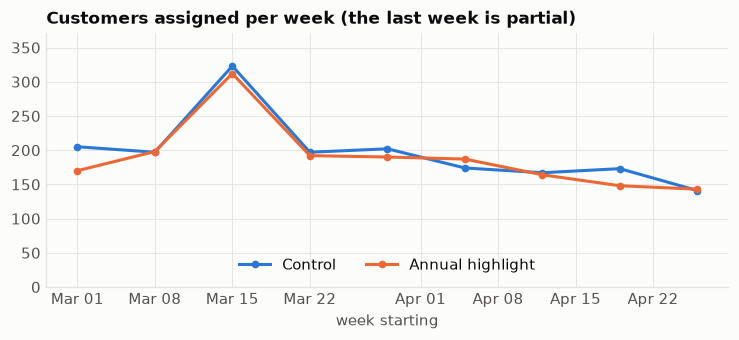

In [4]:
weekly = (
    exposures.assign(week=exposures.assigned_at.dt.to_period("W-SAT").dt.start_time)
    .groupby(["week", "variant"])
    .size()
    .unstack()[[CONTROL, TREATMENT]]
)
fig, ax = plt.subplots(figsize=(8, 3))
for variant in (CONTROL, TREATMENT):
    ax.plot(weekly.index, weekly[variant], color=COLORS[variant], marker="o", markersize=4, label=LABELS[variant])
ax.set_ylim(0, weekly.to_numpy().max() * 1.15)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_xlabel("week starting")
ax.set_title("Customers assigned per week (the last week is partial)")
ax.legend(loc="lower center", ncol=2)
plt.show()

## 4. Power: what could this test see?

The sample was fixed by two months of web signups, so the useful question is the reverse of the
usual one: with about 1,740 customers per arm, how small an effect could the test detect
(80% power, alpha 5%)?

The test is well sized for the primary metric and for the mechanism. It is not sized to *prove
harm* on the guardrail: a real 2-point drop in paid conversion would be detected about one time in
four. That is why the guardrail is read from the confidence interval (can a 2-point drop be ruled
out?) and not from a significance test (was a drop detected?).

In [5]:
control = exposures[~is_treated]
n_arm = (n_c + n_t) / 2
metrics = {
    "chose_annual": ("Annual plan share", "rate"),
    "paid_within_window": ("Paid within 14 days", "rate"),
    "revenue_180d": ("Revenue per signup, 180 days", "usd"),
}
rows = []
for column, (label, kind) in metrics.items():
    base, sd = control[column].mean(), control[column].std()
    mde = minimum_detectable_effect(sd, n_arm)
    rows.append(
        {
            "metric": label,
            "control baseline": pct(base) if kind == "rate" else usd(base),
            "MDE (absolute)": pp(mde).lstrip("+") if kind == "rate" else usd(mde),
            "MDE (relative)": pct(mde / base),
        }
    )
display(pd.DataFrame(rows).set_index("metric"))

sd_paid = control.paid_within_window.std()
print(
    f"Power to detect a {GUARDRAIL_MARGIN * 100:.0f}-point drop in paid conversion with this sample: "
    f"{pct(achieved_power(sd_paid, n_arm, GUARDRAIL_MARGIN), 0)}"
)
print(
    f"Sample needed for 80% power on that drop: {required_sample_size(sd_paid, GUARDRAIL_MARGIN):,} per arm "
    f"({required_sample_size(sd_paid, GUARDRAIL_MARGIN) / n_arm:.1f}x this test)"
)

,control baseline,MDE (absolute),MDE (relative)
metric,,,
Annual plan share,14.7%,3.4 pp,22.9%
Paid within 14 days,60.3%,4.6 pp,7.7%
"Revenue per signup, 180 days",$32.40,$3.20,9.9%


Power to detect a 2-point drop in paid conversion with this sample: 23%
Sample needed for 80% power on that drop: 9,399 per arm (5.4x this test)


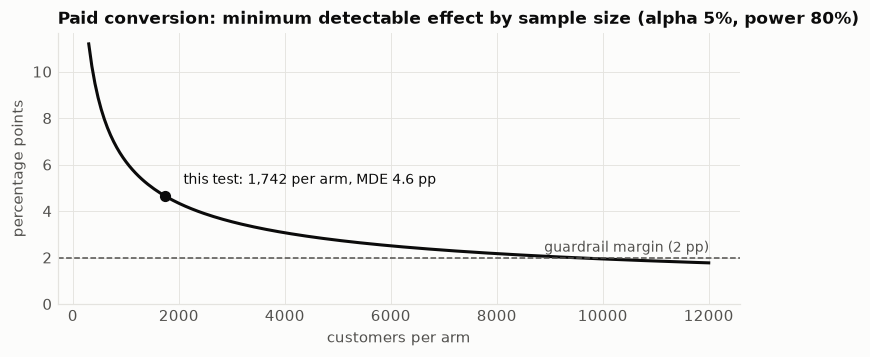

In [6]:
sizes = np.linspace(300, 12_000, 200)
mde_curve = [minimum_detectable_effect(sd_paid, n) for n in sizes]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(sizes, np.array(mde_curve) * 100, color=INK)
ax.axhline(GUARDRAIL_MARGIN * 100, color=MUTED, linewidth=1, linestyle="--")
ax.text(sizes[-1], GUARDRAIL_MARGIN * 100 + 0.25, "guardrail margin (2 pp)", ha="right", color=MUTED, fontsize=9)
mde_now = minimum_detectable_effect(sd_paid, n_arm) * 100
ax.scatter([n_arm], [mde_now], color=INK, zorder=3, s=40)
ax.annotate(
    f"this test: {n_arm:,.0f} per arm, MDE {mde_now:.1f} pp",
    (n_arm, mde_now),
    xytext=(12, 8),
    textcoords="offset points",
    fontsize=9,
)
ax.set_ylim(0, None)
ax.set_xlabel("customers per arm")
ax.set_ylabel("percentage points")
ax.set_title("Paid conversion: minimum detectable effect by sample size (alpha 5%, power 80%)")
plt.show()

## 5. Results

Differences are annual highlight minus control. The relative lift interval uses the delta method,
since the control mean in the denominator is itself estimated. Revenue per signup is skewed (many
zeros, a spike at the annual price), so the normal interval is checked against a bootstrap.

In [7]:
treated = exposures[is_treated]
effects = {
    column: difference_in_means(control[column], treated[column], alpha=ALPHA) for column in [*metrics, "revenue_30d"]
}
metrics["revenue_30d"] = ("Revenue per signup, 30 days", "usd")


def describe(effect, kind):
    if kind == "rate":
        return {
            "control": pct(effect.control_mean),
            "annual_highlight": pct(effect.treatment_mean),
            "difference": pp(effect.diff),
            "95% CI": f"[{pp(effect.ci_low)}, {pp(effect.ci_high)}]",
        }
    return {
        "control": usd(effect.control_mean),
        "annual_highlight": usd(effect.treatment_mean),
        "difference": usd(effect.diff, True),
        "95% CI": f"[{usd(effect.ci_low, True)}, {usd(effect.ci_high, True)}]",
    }


results = pd.DataFrame(
    [
        {
            "metric": metrics[c][0],
            **describe(e, metrics[c][1]),
            "relative lift": f"{pct(e.rel_diff)} [{pct(e.rel_ci_low)}, {pct(e.rel_ci_high)}]",
            "p-value": "< 0.0001" if e.p_value < 1e-4 else f"{e.p_value:.4f}",
        }
        for c, e in effects.items()
    ]
).set_index("metric")
display(results)

primary = effects["revenue_180d"]
boot_low, boot_high = bootstrap_diff_ci(control.revenue_180d, treated.revenue_180d)
print(
    f"180-day revenue difference, bootstrap 95% CI: [{usd(boot_low, True)}, {usd(boot_high, True)}] "
    f"(normal approximation: [{usd(primary.ci_low, True)}, {usd(primary.ci_high, True)}])"
)

,control,annual_highlight,difference,95% CI,relative lift,p-value
metric,,,,,,
Annual plan share,14.7%,25.9%,+11.2 pp,"[+8.5 pp, +13.8 pp]","75.7% [51.5%, 99.9%]",< 0.0001
Paid within 14 days,60.3%,63.7%,+3.4 pp,"[+0.1 pp, +6.6 pp]","5.6% [0.1%, 11.1%]",0.0411
"Revenue per signup, 180 days",$32.40,$38.42,+$6.01,"[+$3.69, +$8.34]","18.6% [10.7%, 26.4%]",< 0.0001
"Revenue per signup, 30 days",$16.18,$24.83,+$8.65,"[+$6.52, +$10.77]","53.4% [37.3%, 69.6%]",< 0.0001


180-day revenue difference, bootstrap 95% CI: [+$3.69, +$8.27] (normal approximation: [+$3.69, +$8.34])


**Reading.** All three pre-declared metrics move the right way and the bootstrap agrees with the
normal interval to within a few cents. Paid conversion is up 3.4 points with p = 0.04; that is one
of three metrics read without a multiplicity correction, so it is treated as "no harm", not as a win.

### Why paid conversion went up

Annual plans have no trial: the customer pays at signup. Moving people from monthly to annual
therefore raises the share that pays within 14 days by construction. The split below shows it,
with a warning attached: the billing period is chosen *after* seeing the paywall, so the rows are
not randomised groups. The variant pulled the customers most likely to pay out of the monthly
group, which is enough to explain its lower trial conversion (51.8% vs 53.9%). Comparing monthly
with monthly across arms is not a causal estimate; only the overall rate is.

In [8]:
by_plan = (
    exposures.assign(plan=np.where(exposures.chose_annual == 1, "annual", "monthly"))
    .groupby(["plan", "variant"])
    .agg(
        customers=("customer_id", "size"),
        paid_within_14d=("paid_within_window", "mean"),
        revenue_180d=("revenue_180d", "mean"),
    )
)
by_plan["paid_within_14d"] = by_plan.paid_within_14d.map(pct)
by_plan["revenue_180d"] = by_plan.revenue_180d.map(usd)
display(by_plan)

customers paid_within_14d revenue_180d
plan    variant                                                 
annual  annual_highlight        441           97.7%       $82.17
        control                 262           97.3%       $81.16
monthly annual_highlight       1263           51.8%       $23.14
        control                1517           53.9%       $23.98

## 6. Revenue over time: why the horizon matters

Cumulative revenue per signup by days since assignment, and the difference between arms with its
confidence interval at every horizon.

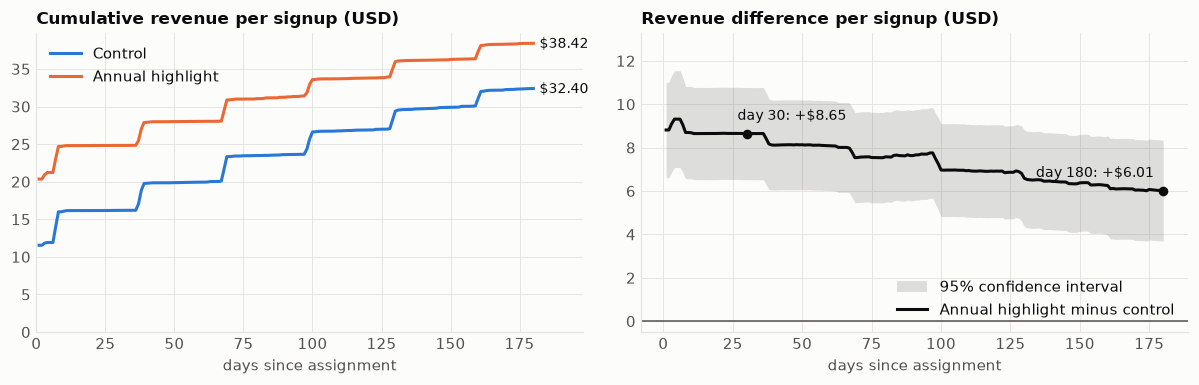

Lead at day 30: +$8.65   at day 180: +$6.01
The lead changed by -$0.45 per month over the last 60 days. If that pace held to day 365 the lead would be about +$3.23 (a straight-line extrapolation, not an estimate).


In [9]:
days = np.arange(1, HORIZON_DAYS + 1)
curve = [difference_in_means(cumulative[~is_treated, d], cumulative[is_treated, d]) for d in range(HORIZON_DAYS)]
diff = np.array([e.diff for e in curve])
low, high = np.array([e.ci_low for e in curve]), np.array([e.ci_high for e in curve])

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
for variant, mask in ((CONTROL, ~is_treated), (TREATMENT, is_treated)):
    mean = cumulative[mask].mean(axis=0)
    left.plot(days, mean, color=COLORS[variant], label=LABELS[variant])
    left.annotate(usd(mean[-1]), (days[-1], mean[-1]), xytext=(4, -3), textcoords="offset points", fontsize=9)
left.set_xlim(0, HORIZON_DAYS + 18)
left.set_ylim(0, None)
left.set_title("Cumulative revenue per signup (USD)")
left.set_xlabel("days since assignment")
left.legend(loc="upper left")

right.fill_between(days, low, high, color=MUTED, alpha=0.18, linewidth=0, label="95% confidence interval")
right.plot(days, diff, color=INK, label="Annual highlight minus control")
right.axhline(0, color=MUTED, linewidth=1)
for d in (30, HORIZON_DAYS):
    right.scatter([d], [diff[d - 1]], color=INK, s=28, zorder=3)
    right.annotate(
        f"day {d}: {usd(diff[d - 1], True)}",
        (d, diff[d - 1]),
        xytext=(-6, 9),
        textcoords="offset points",
        fontsize=9,
        ha="right" if d > 90 else "left",
    )
right.set_ylim(min(0, low.min()) - 0.5, high.max() * 1.15)
right.set_title("Revenue difference per signup (USD)")
right.set_xlabel("days since assignment")
right.legend(loc="lower right")
plt.tight_layout()
plt.show()

slope = (diff[-1] - diff[-61]) / 60
projected = diff[-1] + slope * (365 - HORIZON_DAYS)
print(f"Lead at day 30: {usd(diff[29], True)}   at day {HORIZON_DAYS}: {usd(diff[-1], True)}")
print(
    f"The lead changed by {usd(slope * 30, True)} per month over the last 60 days. If that pace held to day 365 "
    f"the lead would be about {usd(projected, True)} (a straight-line extrapolation, not an estimate)."
)

**Reading.** The variant's lead is largest in the first month (+\$8.65), when annual prepayments have
landed and monthly customers have paid once. Then control catches up a little with every monthly
renewal: +\$6.01 at day 180, shrinking by about \$0.45 a month. A straight line to day 365 leaves a
lead near \$3, still positive. What the data cannot show yet is month 12, when a larger group of
annual customers comes up for renewal at the same time. Reading this test at 30 days would have
reported a lift three times the 180-day one in relative terms (53% vs 19%).

## 7. CUPED

CUPED subtracts from each customer's outcome the part predicted by something known *before*
assignment, which removes variance without moving the expected difference. Its usual covariate is
the same metric in a pre-period. These customers are new: they have no pre-period.

The covariate used instead is a baseline built only from data older than the test: the mean 180-day
revenue of web signups in the same market during the 60 days before the start. It cannot have been
affected by the variant, and it captures real differences in price level between markets.

In [10]:
pre_period = con.sql(f"""
    with cohort as (
        select customer_id, market_code, created_at
        from core.dim_customers
        where signup_platform = 'web'
            and created_at >= timestamp '{start:%Y-%m-%d}' - interval 60 day
            and created_at < timestamp '{start:%Y-%m-%d}'
    )
    select
        cohort.customer_id,
        cohort.market_code,
        coalesce(sum(cast(p.amount_usd_constant_fx as double)), 0) as revenue_180d
    from cohort
    left join finance.fct_payments as p
        on p.customer_id = cohort.customer_id
            and p.payment_status = 'paid'
            and p.billed_at < cohort.created_at + interval {HORIZON_DAYS} day
    group by 1, 2
""").df()

market_baseline = pre_period.groupby("market_code").revenue_180d.mean()
covariate = exposures.market_code.map(market_baseline).fillna(pre_period.revenue_180d.mean()).to_numpy()
adjusted, theta, reduction = cuped_adjust(exposures.revenue_180d, covariate)
raw, cuped = effects["revenue_180d"], difference_in_means(adjusted[~is_treated], adjusted[is_treated])

display(
    pd.DataFrame(
        [
            {
                "estimator": name,
                "difference": usd(e.diff, True),
                "standard error": f"{e.se:.3f}",
                "95% CI": f"[{usd(e.ci_low, True)}, {usd(e.ci_high, True)}]",
            }
            for name, e in (("Difference in means", raw), ("CUPED (pre-period market baseline)", cuped))
        ]
    ).set_index("estimator")
)
print(
    f"Pre-period cohort: {len(pre_period):,} web signups. theta = {theta:.2f}. "
    f"Variance removed: {pct(reduction)} (correlation {np.sqrt(reduction):.2f})."
)
print(f"Same precision with a plain difference in means would need {pct(1 / (1 - reduction) - 1)} more customers.")

,difference,standard error,95% CI
estimator,,,
Difference in means,+$6.01,1.188,"[+$3.69, +$8.34]"
CUPED (pre-period market baseline),+$5.95,1.170,"[+$3.66, +$8.24]"


Pre-period cohort: 3,060 web signups. theta = 0.99. Variance removed: 2.9% (correlation 0.17).
Same precision with a plain difference in means would need 3.0% more customers.


**Reading.** The estimate barely moves and the interval narrows by about 1.5%. The covariate
explains 3% of the variance, because most of the spread in revenue comes from whether a customer
converts and which plan they choose, not from their market. This is the expected result for an
acquisition test, and it is reported as is: CUPED earns its keep in experiments on existing
subscribers (a retention offer, a price change), where last quarter's revenue or watch time often
correlates above 0.7 with the outcome and halves the sample needed. For new-signup tests the
practical levers are sample size and the choice of metric.

## 8. Is the effect the same across markets?

Exploratory. Seven markets were not pre-declared as hypotheses and each has a few hundred
customers, so single-market intervals are wide and some will cross zero by chance alone.

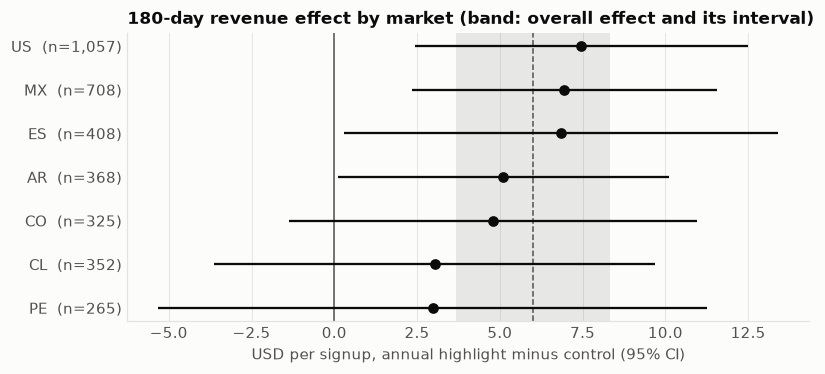

Heterogeneity across markets (Cochran's Q): p = 0.92


In [11]:
segment_rows = []
for market, group in exposures.groupby("market_code"):
    e = difference_in_means(
        group[group.variant == CONTROL].revenue_180d, group[group.variant == TREATMENT].revenue_180d
    )
    segment_rows.append(
        {"market": market, "n": len(group), "diff": e.diff, "se": e.se, "low": e.ci_low, "high": e.ci_high}
    )
segments = pd.DataFrame(segment_rows).sort_values("diff").reset_index(drop=True)

# Cochran's Q: are the per-market effects more spread out than sampling noise explains?
weights = 1 / segments.se**2
pooled = (weights * segments["diff"]).sum() / weights.sum()
q_p = stats.chi2.sf((weights * (segments["diff"] - pooled) ** 2).sum(), len(segments) - 1)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.axvspan(raw.ci_low, raw.ci_high, color=MUTED, alpha=0.12, linewidth=0)
ax.axvline(raw.diff, color=MUTED, linewidth=1, linestyle="--")
ax.axvline(0, color=MUTED, linewidth=1)
ax.hlines(segments.index, segments.low, segments.high, color=INK, linewidth=1.5)
ax.scatter(segments["diff"], segments.index, color=INK, s=36, zorder=3)
ax.set_yticks(segments.index, [f"{m}  (n={n:,})" for m, n in zip(segments.market, segments.n, strict=True)])
ax.grid(axis="y", visible=False)
ax.set_xlabel("USD per signup, annual highlight minus control (95% CI)")
ax.set_title("180-day revenue effect by market (band: overall effect and its interval)")
plt.show()
print(f"Heterogeneity across markets (Cochran's Q): p = {q_p:.2f}")

**Reading.** Every market's estimate is positive and every interval overlaps the overall effect;
the heterogeneity test finds no evidence that markets differ (p = 0.92). There is no basis for a
market-specific rollout.

## 9. Web funnel

The experiment table starts at signup, so it cannot say whether the variant changed how many
visitors sign up in the first place. GA4 sessions give two partial views of that blind spot.

**Before vs during the test.** Step conversion for all web sessions in the eight weeks before the
test and during it. This is not a randomised comparison (season and campaigns differ), and half of
the traffic during the test saw the control paywall, so a real effect would appear diluted.

period,8 weeks before,during the test
sessions,25278,30555
paywall,8560,10206
plan_selected,3444,4181
signup,2531,3074
paid_at_signup,401,629


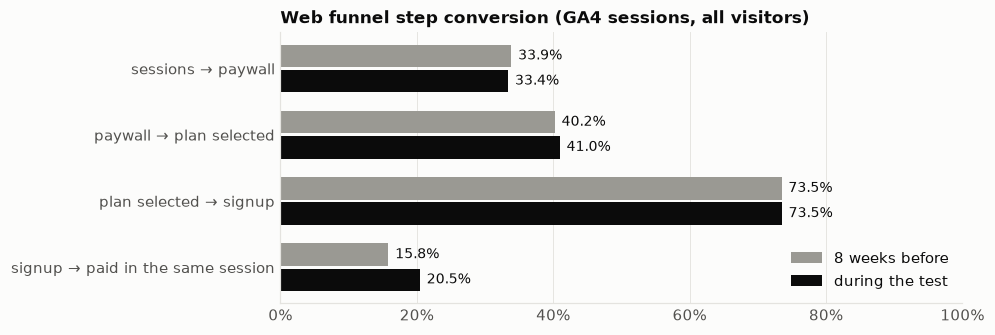

Paywall → signup: 29.6% before, 30.1% during; change +0.6 pp (95% CI [-0.8 pp, +1.9 pp], not randomised)


In [12]:
weeks_before = 8
funnel = (
    con.sql(f"""
    select
        case when activity_date >= date '{start:%Y-%m-%d}' then 'during the test' else '8 weeks before' end as period,
        sum(sessions) as sessions,
        sum(paywall_sessions) as paywall,
        sum(plan_selected_sessions) as plan_selected,
        sum(signup_sessions) as signup,
        sum(purchase_sessions) as paid_at_signup
    from marketing.fct_web_funnel_daily
    where activity_date >= date '{start:%Y-%m-%d}' - interval {weeks_before * 7} day
        and activity_date <= date '{end:%Y-%m-%d}'
    group by 1
""")
    .df()
    .set_index("period")
    .astype(float)
    .loc[["8 weeks before", "during the test"]]
)

steps = {
    "sessions → paywall": ("paywall", "sessions"),
    "paywall → plan selected": ("plan_selected", "paywall"),
    "plan selected → signup": ("signup", "plan_selected"),
    "signup → paid in the same session": ("paid_at_signup", "signup"),
}
rates = pd.DataFrame({name: funnel[num] / funnel[den] for name, (num, den) in steps.items()}).T
display(funnel.astype(int).T)

fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(rates))[::-1]
for offset, (period, color) in zip(
    (0.19, -0.19), (("8 weeks before", "#9a9993"), ("during the test", INK)), strict=True
):
    ax.barh(y + offset, rates[period], height=0.34, color=color, label=period)
    for yi, value in zip(y + offset, rates[period], strict=True):
        ax.text(value + 0.01, yi, pct(value), va="center", fontsize=9)
ax.set_yticks(y, rates.index)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="y", visible=False)
ax.set_title("Web funnel step conversion (GA4 sessions, all visitors)")
ax.legend(loc="lower right")
plt.show()

before, during = funnel.loc["8 weeks before"], funnel.loc["during the test"]
p_b, p_d = before.signup / before.paywall, during.signup / during.paywall
se = np.sqrt(p_b * (1 - p_b) / before.paywall + p_d * (1 - p_d) / during.paywall)
print(
    f"Paywall → signup: {pct(p_b)} before, {pct(p_d)} during; "
    f"change {pp(p_d - p_b)} (95% CI [{pp(p_d - p_b - 1.96 * se)}, {pp(p_d - p_b + 1.96 * se)}], not randomised)"
)

In [13]:
signup_sessions = con.sql("""
    select customer_id, bool_or(purchased) as purchased_in_session
    from marketing.fct_web_sessions
    where signed_up and customer_id is not null
    group by 1
""").df()
tracked = exposures.merge(signup_sessions, on="customer_id", how="left")
tracked["seen_by_ga4"] = tracked.purchased_in_session.notna()
ga4 = tracked.groupby("variant").agg(
    exposed=("customer_id", "size"),
    seen_by_ga4=("seen_by_ga4", "mean"),
    annual_share_billing=("chose_annual", "mean"),
)
ga4["purchase_at_signup_ga4"] = tracked[tracked.seen_by_ga4].groupby("variant").purchased_in_session.mean()
coverage_p = stats.chi2_contingency(pd.crosstab(tracked.variant, tracked.seen_by_ga4)).pvalue
ga4[ga4.columns[1:]] = ga4[ga4.columns[1:]].map(pct)
display(ga4.loc[[CONTROL, TREATMENT]])
print(f"GA4 coverage is the same in both arms: chi-square p = {coverage_p:.2f}")

,exposed,seen_by_ga4,annual_share_billing,purchase_at_signup_ga4
variant,,,,
control,1779,88.1%,14.7%,15.0%
annual_highlight,1704,88.3%,25.9%,26.2%


GA4 coverage is the same in both arms: chi-square p = 0.91


**Reading.** Paywall to signup stayed at 30% (change +0.6 pp, interval from -0.8 to +1.9), so
there is no sign that the variant put visitors off; together with the clean sample ratio, the two
checks point the same way. The one step that moved is the last: signups paying in their first
session rose from 15.8% to 20.5%, which is the annual plan (no trial) showing up in a second,
independent source. In the per-arm view above, GA4 sees the same 88% of signups in both arms, and
its purchase-at-signup share matches the annual share from billing.

## 10. Readout

In [14]:
primary, annual, guardrail = effects["revenue_180d"], effects["chose_annual"], effects["paid_within_window"]
checks = [
    ("Sample ratio", srm_p >= 0.001, f"SRM p = {srm_p:.2f}"),
    (
        "Primary: 180-day revenue per signup",
        primary.ci_low > 0,
        f"{usd(primary.diff, True)} per signup, 95% CI [{usd(primary.ci_low, True)}, {usd(primary.ci_high, True)}], "
        f"lift {pct(primary.rel_diff)}",
    ),
    (
        "Mechanism: annual plan share",
        annual.ci_low > 0,
        f"{pct(annual.control_mean)} -> {pct(annual.treatment_mean)}, "
        f"95% CI [{pp(annual.ci_low)}, {pp(annual.ci_high)}]",
    ),
    (
        f"Guardrail: paid conversion not worse than -{GUARDRAIL_MARGIN * 100:.0f} pp",
        guardrail.ci_low > -GUARDRAIL_MARGIN,
        f"{pp(guardrail.diff)}, 95% CI [{pp(guardrail.ci_low)}, {pp(guardrail.ci_high)}]",
    ),
]
with pd.option_context("display.max_colwidth", None):
    display(
        pd.DataFrame(
            [{"check": name, "result": "pass" if ok else "FAIL", "evidence": text} for name, ok, text in checks]
        ).set_index("check")
    )
decision = "Ship the annual highlight" if all(ok for _, ok, _ in checks) else "Do not ship yet"
display(Markdown(f"**Decision under the rule above: {decision}.**"))

,result,evidence
check,,
Sample ratio,pass,SRM p = 0.20
Primary: 180-day revenue per signup,pass,"+$6.01 per signup, 95% CI [+$3.69, +$8.34], lift 18.6%"
Mechanism: annual plan share,pass,"14.7% -> 25.9%, 95% CI [+8.5 pp, +13.8 pp]"
Guardrail: paid conversion not worse than -2 pp,pass,"+3.4 pp, 95% CI [+0.1 pp, +6.6 pp]"


**Decision under the rule above: Ship the annual highlight.**

### What this readout does not cover

- **Renewals.** The 180-day window ends before any annual plan renews. The variant converts monthly
  payments into one prepayment; whether those customers renew at month 12 decides the long-run
  value. Re-read this test in June 2027, once every exposed customer has passed month 12.
- **Exposure is logged at signup, not at paywall view.** Visitors who saw a paywall and left are in
  neither arm. The sample ratio and the funnel say that did not bias this test, but the next one
  should log assignment when the paywall renders, so signup rate becomes a randomised metric.
- **The guardrail is underpowered to detect harm** (section 4). A 2-point drop is ruled out by the
  interval, not by a powered test; a test more than five times larger would be needed for the latter.
- **The decision rule was written for this readout.** In a live test it is registered before
  launch; here the dataset is synthetic and the rule is stated first to show the practice.
- **Revenue is gross of refunds and at constant FX**, consistent with the marts.